Q1. Student Performance and Correlation Analysis

Study Hours vs Marks: 0.9979419719885523
Attendance vs Marks: 0.9957268450507291


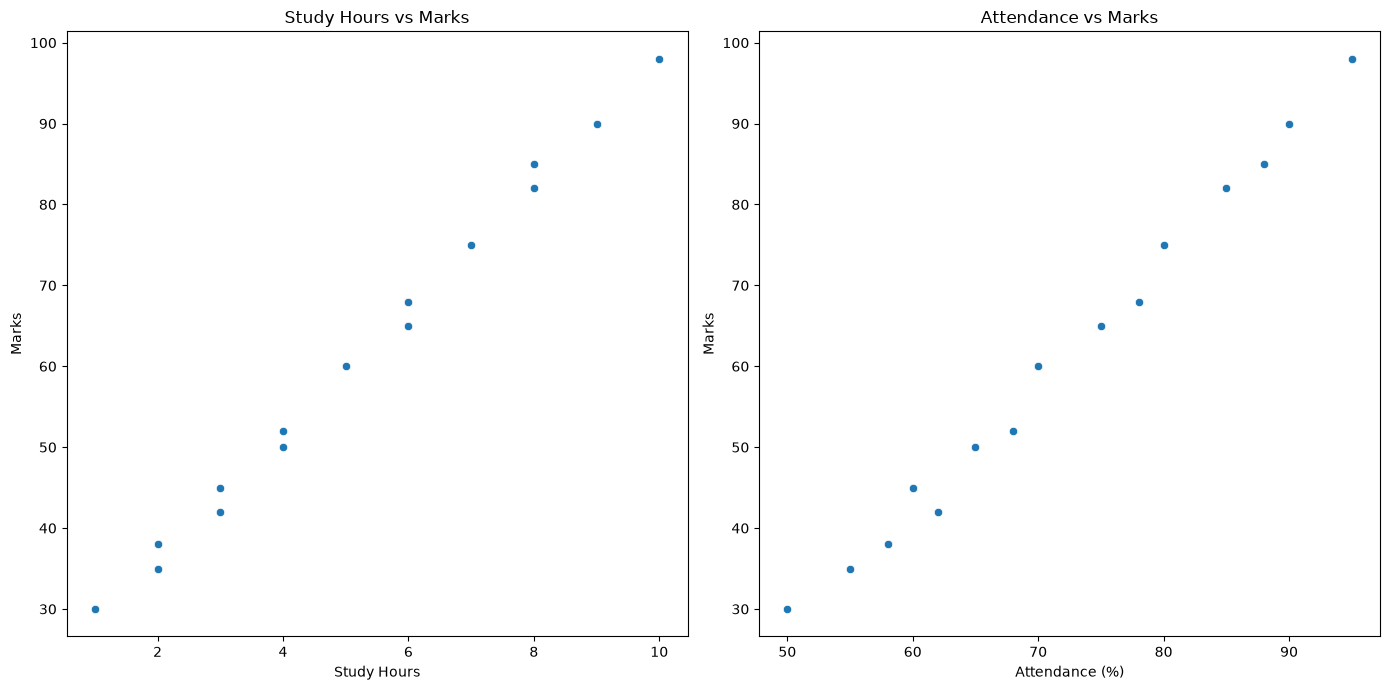

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame
df = pd.DataFrame({
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 2, 4, 6, 8, 3
    ],
    "Attendance": [
        50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 58, 68, 78, 88, 62
    ],
    "Marks": [
        30, 35, 45, 50, 60, 65, 75, 82, 90, 98, 38, 52, 68, 85, 42
    ]
})

# Calculate Pearson correlation
corr_study = df['Study_Hours'].corr(df['Marks'])
corr_attendance = df['Attendance'].corr(df['Marks'])

print("Study Hours vs Marks:", corr_study)
print("Attendance vs Marks:", corr_attendance)

# Create scatter plots
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Study_Hours', y='Marks')
plt.title('Study Hours vs Marks')
plt.xlabel('Study Hours')
plt.ylabel('Marks')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Attendance', y='Marks')
plt.title('Attendance vs Marks')
plt.xlabel('Attendance (%)')
plt.ylabel('Marks')

plt.tight_layout()
plt.show()


(b) Add a hypothetical student and recalculate both correlations.

Updated Study Hours vs Marks: 0.7011972258015061
Updated Attendance vs Marks: 0.996358029483461


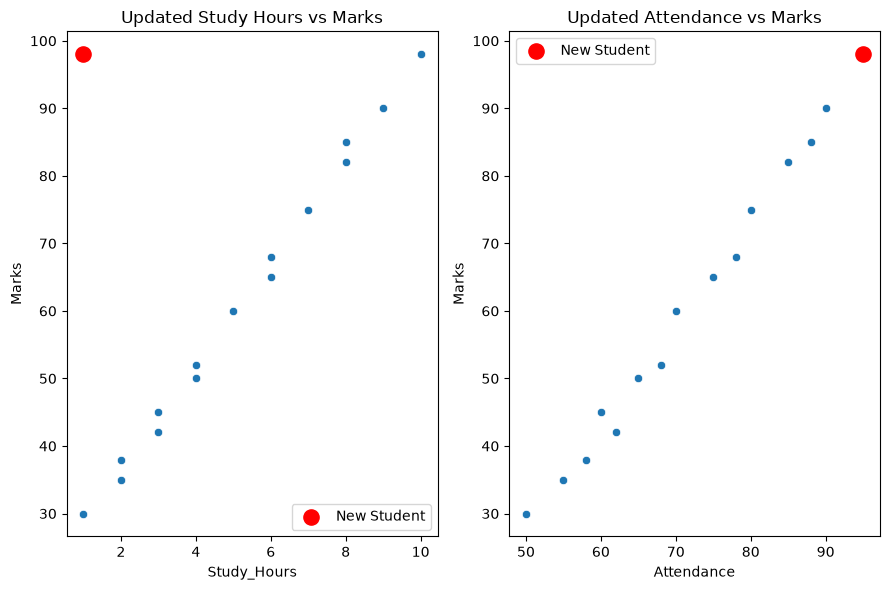

In [11]:

# Add a hypothetical student
new_student = pd.DataFrame({
    "Study_Hours": [1],
    "Attendance": [95],
    "Marks": [98]
})

# Add new observation
df_new = pd.concat([df, new_student], ignore_index=True)

# Recalculate correlation
new_corr_study = df_new['Study_Hours'].corr(df_new['Marks'])
new_corr_attendance = df_new['Attendance'].corr(df_new['Marks'])

print("Updated Study Hours vs Marks:", new_corr_study)
print("Updated Attendance vs Marks:", new_corr_attendance)

# Visualize updated data
plt.figure(figsize=(9, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_new, x='Study_Hours', y='Marks')
plt.scatter(1, 98, color='red', s=120, label='New Student')
plt.title('Updated Study Hours vs Marks')
plt.legend()

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_new, x='Attendance', y='Marks')
plt.scatter(95, 98, color='red', s=120, label='New Student')
plt.title('Updated Attendance vs Marks')
plt.legend()

plt.tight_layout()
plt.show()


Q2. Product Sales: Bar Plot and Business Decisions

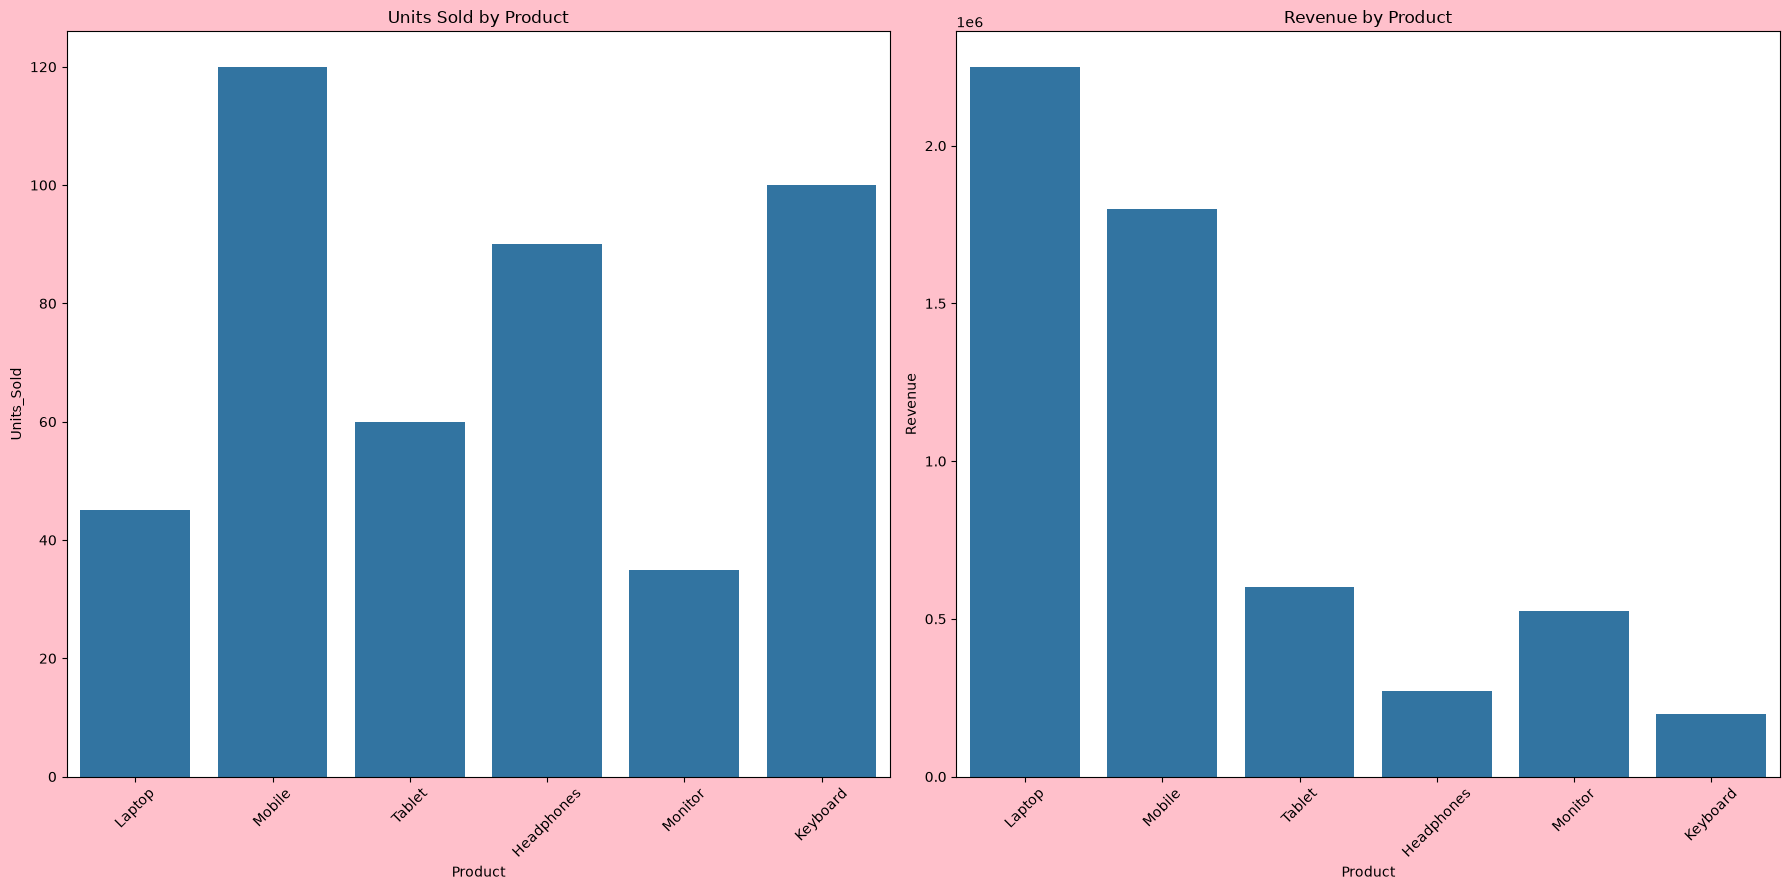

Highest Units Sold:
Product        Mobile
Units_Sold        120
Revenue       1800000
Name: 1, dtype: object

Lowest Units Sold:
Product       Monitor
Units_Sold         35
Revenue        525000
Name: 4, dtype: object

Highest Revenue:
Product        Laptop
Units_Sold         45
Revenue       2250000
Name: 0, dtype: object

Lowest Revenue:
Product       Keyboard
Units_Sold         100
Revenue         200000
Name: 5, dtype: object

Revenue Contribution:
      Product  Revenue_Percentage
0      Laptop               39.86
1      Mobile               31.89
2      Tablet               10.63
3  Headphones                4.78
4     Monitor                9.30
5    Keyboard                3.54


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame
df = pd.DataFrame({
    "Product": [
        "Laptop", "Mobile", "Tablet",
        "Headphones", "Monitor", "Keyboard"
    ],
    "Units_Sold": [45, 120, 60, 90, 35, 100],
    "Revenue": [
        2250000, 1800000, 600000,
        270000, 525000, 200000
    ]
})

# Create two bar plots
plt.figure(figsize=(18, 9),facecolor = 'pink')

plt.subplot(1, 2, 1)
sns.barplot(data=df, x='Product', y='Units_Sold')
plt.title('Units Sold by Product')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.barplot(data=df, x='Product', y='Revenue')
plt.title('Revenue by Product')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Highest and lowest products
print("Highest Units Sold:")
print(df.loc[df['Units_Sold'].idxmax()])

print("\nLowest Units Sold:")
print(df.loc[df['Units_Sold'].idxmin()])

print("\nHighest Revenue:")
print(df.loc[df['Revenue'].idxmax()])

print("\nLowest Revenue:")
print(df.loc[df['Revenue'].idxmin()])

# Revenue contribution percentage
total_revenue = df['Revenue'].sum()

df['Revenue_Percentage'] = (
    df['Revenue'] / total_revenue
) * 100

print("\nRevenue Contribution:")
print(df[['Product', 'Revenue_Percentage']].round(2))


(b) Calculate Revenue per Unit and create a ranking bar plot.

Revenue Per Unit:
      Product  Revenue_Per_Unit
0      Laptop           50000.0
1      Mobile           15000.0
4     Monitor           15000.0
2      Tablet           10000.0
3  Headphones            3000.0
5    Keyboard            2000.0


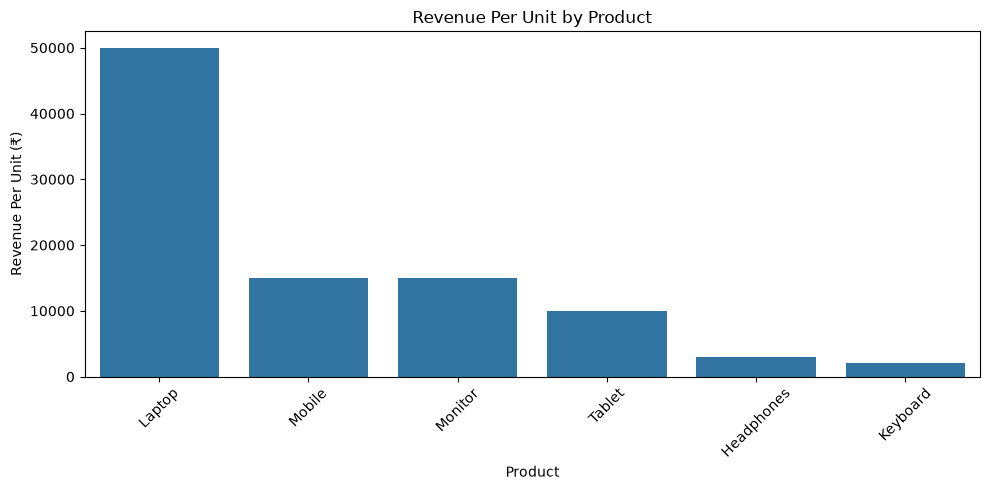


High Sales but Low Revenue Per Unit:
      Product  Units_Sold  Revenue_Per_Unit
3  Headphones          90            3000.0
5    Keyboard         100            2000.0


In [20]:

# Calculate revenue per unit
df['Revenue_Per_Unit'] = (
    df['Revenue'] / df['Units_Sold']
)

# Sort products by revenue per unit
df_sorted = df.sort_values(
    by='Revenue_Per_Unit',
    ascending=False
)

print("Revenue Per Unit:")
print(df_sorted[['Product', 'Revenue_Per_Unit']])

# Create bar plot
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_sorted,
    x='Product',
    y='Revenue_Per_Unit'
)

plt.title('Revenue Per Unit by Product')
plt.xlabel('Product')
plt.ylabel('Revenue Per Unit (₹)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Identify high sales but low revenue per unit
print("\nHigh Sales but Low Revenue Per Unit:")

result = df[
    (df['Units_Sold'] >= 90) &
    (df['Revenue_Per_Unit'] <= 3000)
]

print(result[['Product', 'Units_Sold', 'Revenue_Per_Unit']])


Q3. Correlation Investigation Using the Tips Dataset

Total Bill vs Tip: 0.6757341092113645
Party Size vs Tip: 0.48929877523035725


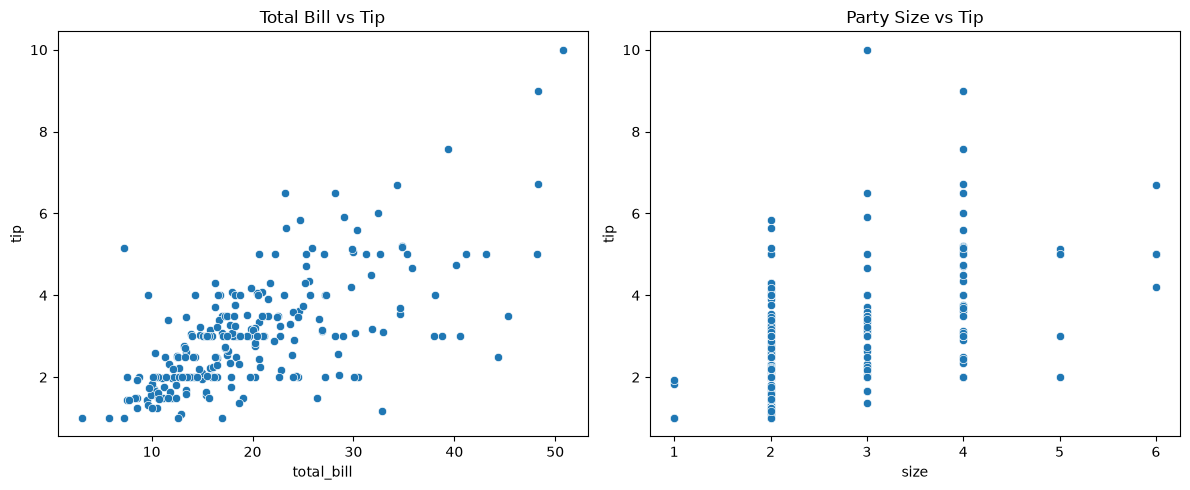

In [21]:

import seaborn as sns
import matplotlib.pyplot as plt

# Load Tips dataset
df = sns.load_dataset('tips')

# Calculate correlation
corr_bill_tip = df['total_bill'].corr(df['tip'])
corr_size_tip = df['size'].corr(df['tip'])

print("Total Bill vs Tip:", corr_bill_tip)
print("Party Size vs Tip:", corr_size_tip)

# Create scatter plots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='total_bill', y='tip')
plt.title('Total Bill vs Tip')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='size', y='tip')
plt.title('Party Size vs Tip')

plt.tight_layout()
plt.show()


(b) Calculate average tip by party size and create a bar plot.

Average Tip by Party Size:
size
1    1.437500
2    2.582308
3    3.393158
4    4.135405
5    4.028000
6    5.225000
Name: tip, dtype: float64


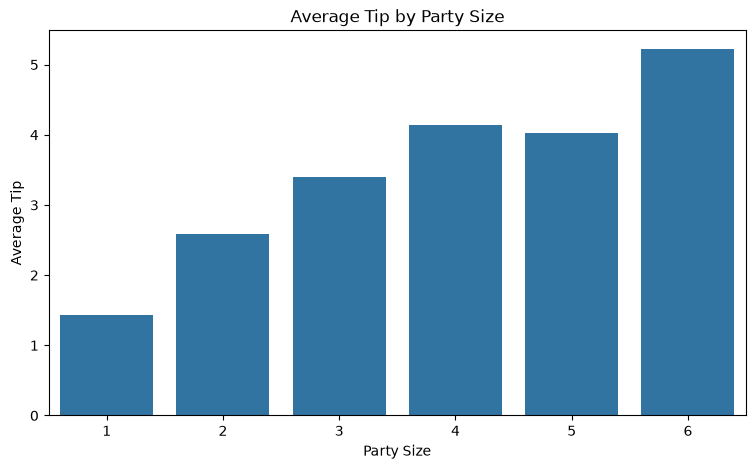

In [22]:

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = sns.load_dataset('tips')

# Group by party size and calculate average tip
average_tip = df.groupby('size', observed=True)['tip'].mean()

print("Average Tip by Party Size:")
print(average_tip)

# Create bar plot
plt.figure(figsize=(9, 5))

sns.barplot(
    x=average_tip.index,
    y=average_tip.values
)

plt.title('Average Tip by Party Size')
plt.xlabel('Party Size')
plt.ylabel('Average Tip')

plt.show()


Q4. Comparing Positive, Negative, and Weak Correlations

(a) Create scatter plots and calculate both Pearson correlation coefficients.

Advertising Cost vs Sales: -0.9964517924788717
Advertising Cost vs Customer Satisfaction: 0.08879923794435521


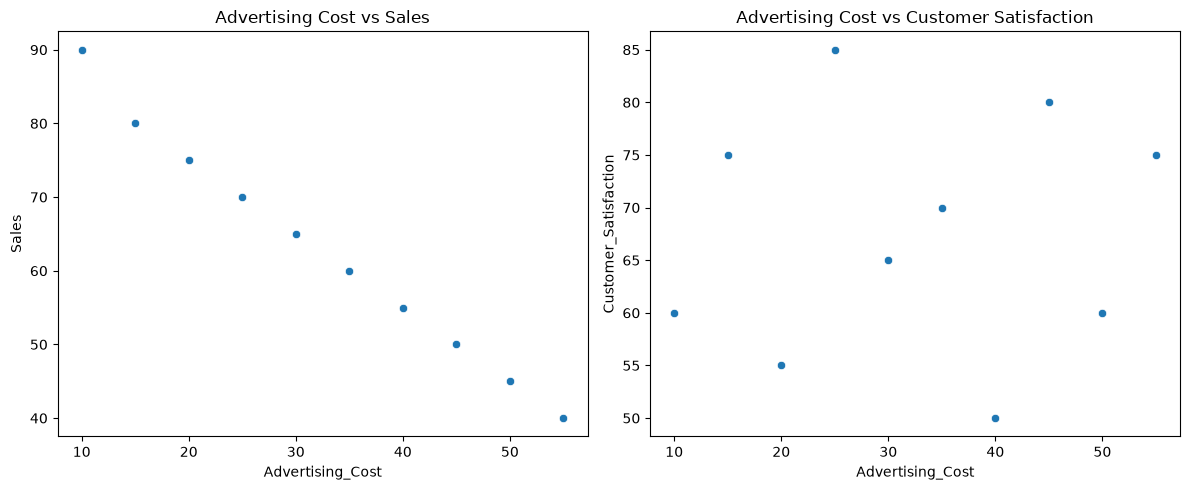

In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame
df = pd.DataFrame({
    "Campaign": [
        "A", "B", "C", "D", "E",
        "F", "G", "H", "I", "J"
    ],

    "Advertising_Cost": [
        10, 15, 20, 25, 30,
        35, 40, 45, 50, 55
    ],

    "Sales": [
        90, 80, 75, 70, 65,
        60, 55, 50, 45, 40
    ],

    "Customer_Satisfaction": [
        60, 75, 55, 85, 65,
        70, 50, 80, 60, 75
    ]
})

# Calculate Pearson correlation
corr_sales = df['Advertising_Cost'].corr(df['Sales'])

corr_satisfaction = df['Advertising_Cost'].corr(
    df['Customer_Satisfaction']
)

print("Advertising Cost vs Sales:", corr_sales)

print("Advertising Cost vs Customer Satisfaction:",
      corr_satisfaction)

# Create scatter plots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.scatterplot(
    data=df,
    x='Advertising_Cost',
    y='Sales'
)

plt.title('Advertising Cost vs Sales')

plt.subplot(1, 2, 2)

sns.scatterplot(
    data=df,
    x='Advertising_Cost',
    y='Customer_Satisfaction'
)

plt.title('Advertising Cost vs Customer Satisfaction')

plt.tight_layout()
plt.show()


(b) Add a new campaign and recalculate correlation.

Original Correlation: -0.9964517924788717
Updated Correlation: 0.5684135293216566


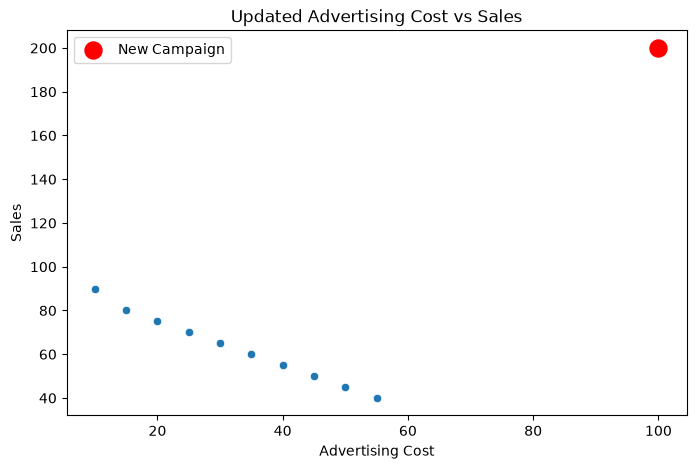

In [24]:

# Add a new campaign
new_campaign = pd.DataFrame({
    "Campaign": ["K"],
    "Advertising_Cost": [100],
    "Sales": [200],
    "Customer_Satisfaction": [None]
})

# Add new campaign to original DataFrame
df_new = pd.concat(
    [df, new_campaign],
    ignore_index=True
)

# Recalculate correlation
new_corr = df_new['Advertising_Cost'].corr(
    df_new['Sales']
)

print("Original Correlation:", corr_sales)

print("Updated Correlation:", new_corr)

# Create updated scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_new,
    x='Advertising_Cost',
    y='Sales'
)

# Highlight new campaign
plt.scatter(
    100, 200,
    color='red',
    s=150,
    label='New Campaign'
)

plt.title('Updated Advertising Cost vs Sales')
plt.xlabel('Advertising Cost')
plt.ylabel('Sales')

plt.legend()
plt.show()
